# 时频变换算法交互式分析工具

本Notebook用于验证和调优各种时频变换算法的处理效果。

## 功能特点
- 支持12种时频变换算法
- 去直流/去趋势预处理（防止近零Hz异常大值）
- 参数调整范围标注
- 简化实现，快速执行

In [4]:
# 0. 自动安装依赖（如缺失）
import subprocess
import sys

required_packages = ['matplotlib', 'numpy', 'scipy', 'pywavelets']
missing = []
for pkg in required_packages:
    try:
        __import__(pkg.replace('pywavelets', 'pywt'))
    except ImportError:
        missing.append(pkg)

if missing:
    print(f'安装缺失依赖: {missing}')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install'] + missing)
else:
    print('所有依赖已安装')

所有依赖已安装


In [1]:
# 1. 环境配置
import matplotlib
matplotlib.use('inline')

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import spectrogram, hilbert, welch
import pywt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 6)

print('环境配置完成!')

环境配置完成!


In [3]:
# 2. 生成测试信号
FS = 400000
DURATION = 0.3
N = int(FS * DURATION)
t = np.linspace(0, DURATION, N, endpoint=False)

# 信号组成：直流偏移 + 趋势 + 100Hz + 500Hz调幅 + 冲击 + 噪声
raw_signal = 5.0 + 0.3*t + 2.0*np.sin(2*np.pi*100*t) + (1+0.5*np.sin(2*np.pi*5*t))*np.sin(2*np.pi*500*t) + 0.2*np.random.randn(N)

# 添加冲击
for it in [0.1, 0.2]:
    idx = int(it * FS)
    if idx < N:
        raw_signal[idx] += 10.0

# 预处理：去直流+去趋势
processed_signal = raw_signal - np.mean(raw_signal)
processed_signal = signal.detrend(processed_signal)

print('信号长度:', N, '采样点')
print('采样频率:', FS, 'Hz')

信号长度: 120000 采样点
采样频率: 400000 Hz


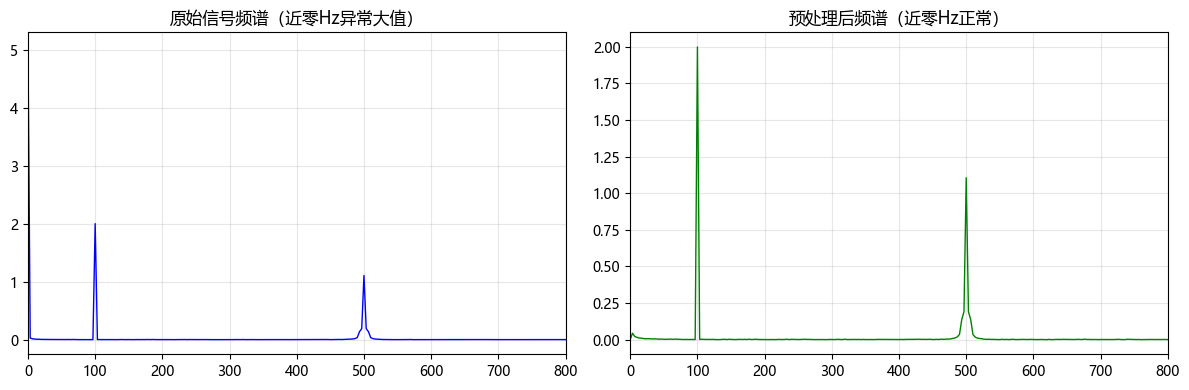

预处理已消除直流偏移和低频趋势


In [4]:
# 3. 预处理效果对比
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# 原始信号频谱
freqs_raw = np.fft.rfftfreq(N, 1/FS)
mag_raw = np.abs(np.fft.rfft(raw_signal))/N; mag_raw[1:]*=2
ax[0].plot(freqs_raw, mag_raw, 'b-', lw=1)
ax[0].set_title('原始信号频谱（近零Hz异常大值）')
ax[0].set_xlim([0, 800]); ax[0].grid(True, alpha=0.3)

# 处理后频谱
mag_proc = np.abs(np.fft.rfft(processed_signal))/N; mag_proc[1:]*=2
ax[1].plot(freqs_raw, mag_proc, 'g-', lw=1)
ax[1].set_title('预处理后频谱（近零Hz正常）')
ax[1].set_xlim([0, 800]); ax[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print('预处理已消除直流偏移和低频趋势')


STFT 参数对比


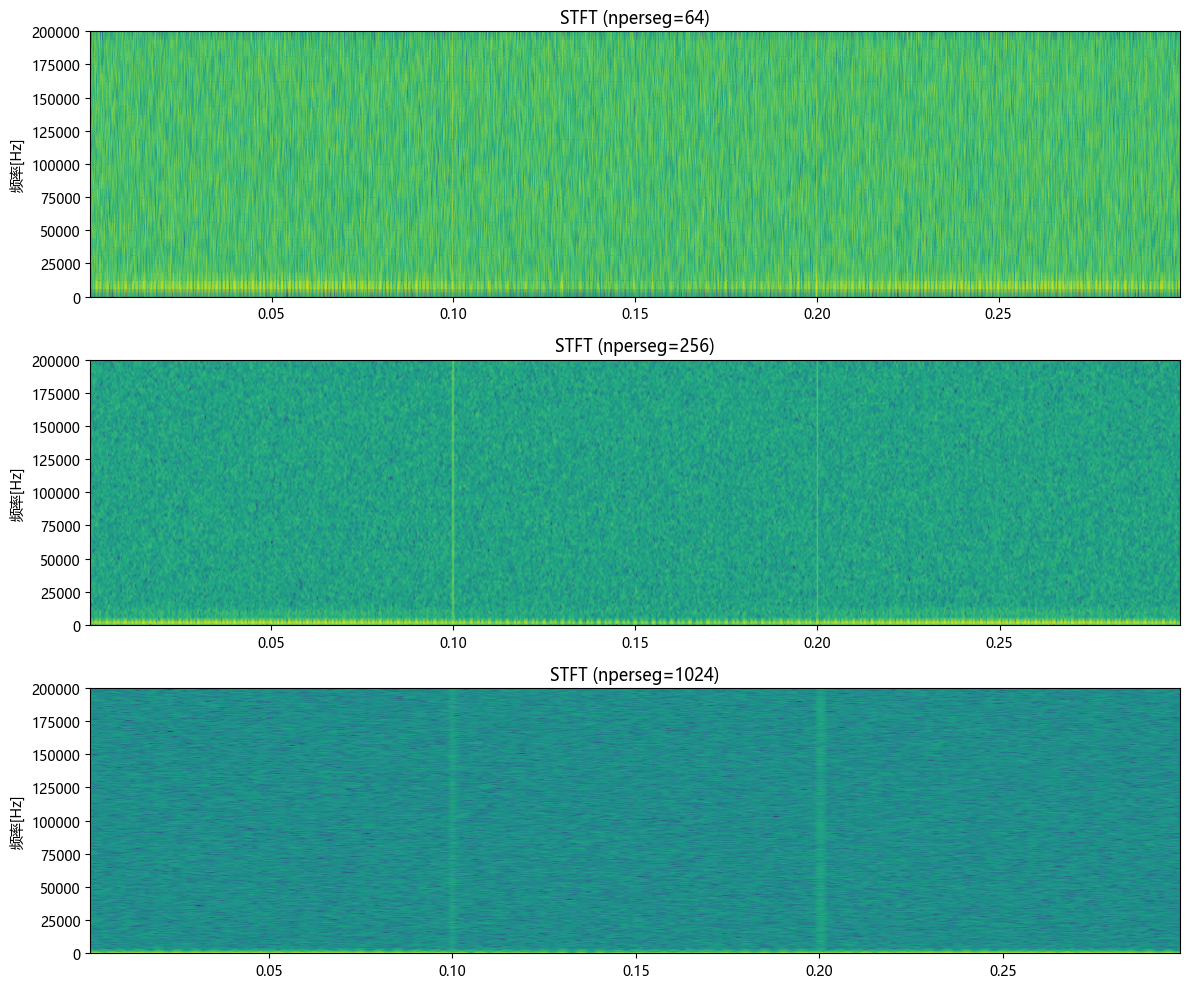

In [5]:
# 4. STFT (短时傅里叶变换)
# 参数: nperseg=窗长(16~N/2), noverlap=重叠(推荐nperseg*0.5~0.75)
print('\n' + '='*50)
print('STFT 参数对比')
print('='*50)

fig, ax = plt.subplots(3, 1, figsize=(12, 10))
for i, nperseg in enumerate([64, 256, min(1024, N//2)]):
    f, t_s, Sxx = spectrogram(processed_signal, FS, nperseg=nperseg, noverlap=nperseg//2)
    ax[i].pcolormesh(t_s, f, 10*np.log10(Sxx+1e-12), shading='gouraud')
    ax[i].set_title('STFT (nperseg=%d)' % nperseg)
    ax[i].set_ylabel('频率[Hz]')
plt.tight_layout(); plt.show()


CWT 连续小波变换


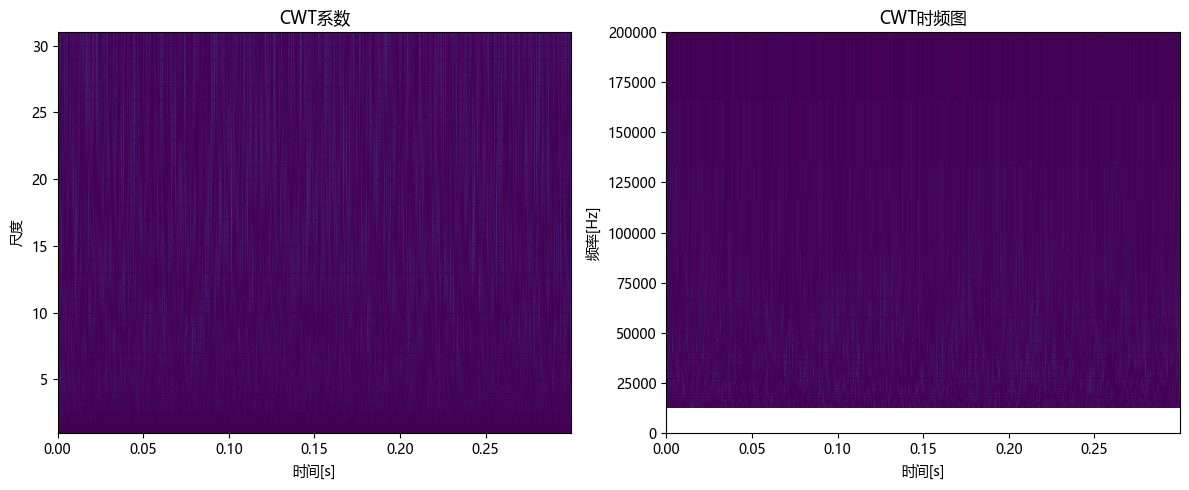

In [7]:
# 5. CWT (连续小波变换)
# 参数: wavelet=小波基(cmor*, mexh), scales=尺度范围(1~N/4)
print('\n' + '='*50)
print('CWT 连续小波变换')
print('='*50)

scales = np.arange(1, 32)
coef, freqs_cwt = pywt.cwt(processed_signal, scales, 'cmor1.5-1.0', 1/FS)
t_wave = np.arange(N)/FS

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].pcolormesh(t_wave, scales, np.abs(coef), shading='gouraud')
ax[0].set_title('CWT系数'); ax[0].set_xlabel('时间[s]'); ax[0].set_ylabel('尺度')
ax[1].pcolormesh(t_wave, freqs_cwt, np.abs(coef), shading='gouraud')
ax[1].set_title('CWT时频图'); ax[1].set_xlabel('时间[s]'); ax[1].set_ylabel('频率[Hz]')
ax[1].set_ylim([0, FS/2])
plt.tight_layout(); plt.show()

In [ ]:
# 6. DWT (离散小波变换)
# 参数: wavelet=小波基(db*, sym*, coif*), level=分解层数(1~log2(N))
print('\n' + '='*50)
print('DWT 离散小波变换')
print('='*50)

wavelet = 'db4'
max_level = min(pywt.dwt_max_level(N, wavelet), 5)
coeffs = pywt.wavedec(processed_signal, wavelet, level=max_level)
labels = ['A%d' % max_level] + ['D%d' % i for i in range(max_level, 0, -1)]
energies = [np.sum(c**2) for c in coeffs]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].bar(labels, energies, color='steelblue', edgecolor='black')
ax[0].set_title('DWT各频带能量 (wavelet=%s, level=%d)' % (wavelet, max_level))
ax[0].grid(True, alpha=0.3, axis='y')

for i, (c, label) in enumerate(zip(coeffs, labels)):
    ax[1].plot(np.linspace(0, DURATION, len(c)), c/np.max(np.abs(c)+1e-12)+i, label=label)
ax[1].set_title('各层系数(归一化)')
ax[1].legend(loc='upper right'); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# 7. WPT (小波包变换)
# 参数: wavelet, maxlevel=分解层数
print('\n' + '='*50)
print('WPT 小波包变换')
print('='*50)

wavelet = 'db4'
max_level = 4
try:
    wp = pywt.WaveletPacket(processed_signal, wavelet, 'symmetric', maxlevel=max_level)
    nodes = [n.path for n in wp.get_level(max_level, 'freq')]
    energies = [np.sum(wp[n].data**2) for n in nodes]
    
    plt.figure(figsize=(12, 4))
    plt.bar(range(len(energies)), energies, color='coral', edgecolor='black')
    plt.title('WPT各频带能量 (共%d带)' % len(energies))
    plt.grid(True, alpha=0.3, axis='y')
    plt.show()
except Exception as e:
    print('WPT计算失败:', e)

In [ ]:
# 8. Hilbert变换 (瞬时幅值/频率)
# 参数: 无关键参数
print('\n' + '='*50)
print('Hilbert变换')
print('='*50)

analytic = hilbert(processed_signal)
inst_amp = np.abs(analytic)
inst_freq = np.diff(np.unwrap(np.angle(analytic)))/(2*np.pi)*FS

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(t, processed_signal, 'b-', lw=0.5, alpha=0.5, label='信号')
ax[0].plot(t, inst_amp, 'r-', lw=1, label='瞬时幅值')
ax[0].set_title('瞬时幅值'); ax[0].legend(); ax[0].grid(True, alpha=0.3)
ax[1].plot(t[:-1], inst_freq, 'g-', lw=0.5)
ax[1].set_title('瞬时频率'); ax[1].set_ylim([0, FS/2]); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# 9. Welch功率谱密度
# 参数: nperseg=窗长(64~4096)
print('\n' + '='*50)
print('Welch功率谱密度')
print('='*50)

plt.figure(figsize=(12, 5))
for nperseg in [64, 256, min(1024, N//2)]:
    f_psd, Pxx = welch(processed_signal, FS, nperseg=nperseg, noverlap=nperseg//2)
    plt.semilogy(f_psd, Pxx, lw=1, label='nperseg=%d' % nperseg)
plt.title('Welch功率谱密度对比')
plt.xlim([0, FS/2]); plt.legend(); plt.grid(True, alpha=0.3)
plt.xlabel('频率[Hz]'); plt.ylabel('PSD')
plt.show()

In [ ]:
# 10. Gabor变换 (高斯窗STFT)
# 参数: n_windows=时间窗口数(20~200)
print('\n' + '='*50)
print('Gabor变换')
print('='*50)

n_win = 25
nperseg_g = max(16, min(N//n_win, N))
window_g = signal.windows.gaussian(nperseg_g, nperseg_g/6)
f_g, t_g, G = spectrogram(processed_signal, FS, window=window_g, nperseg=nperseg_g, noverlap=nperseg_g//2)

plt.figure(figsize=(12, 5))
plt.pcolormesh(t_g, f_g, 10*np.log10(G+1e-12), shading='gouraud')
plt.title('Gabor变换时频图')
plt.xlabel('时间[s]'); plt.ylabel('频率[Hz]')
plt.colorbar(label='dB')
plt.show()

In [ ]:
# 11. 短时自相关
# 参数: window_size=分析窗长(64~2048)
print('\n' + '='*50)
print('短时自相关')
print('='*50)

ws = 128
hop = ws//2
n_windows = max(1, (N-ws)//hop+1)
ac_matrix = np.zeros((n_windows, ws//2))

for i in range(n_windows):
    seg = processed_signal[i*hop:i*hop+ws]
    if len(seg) >= ws//2:
        corr = np.correlate(seg, seg, 'full')
        corr = corr[len(corr)//2:len(corr)//2+ws//2]
        ac_matrix[i] = corr/(corr[0]+1e-12)

time_axis = np.linspace(0, DURATION, n_windows)
lag_axis = np.arange(ws//2)/FS

plt.figure(figsize=(12, 5))
plt.pcolormesh(time_axis, lag_axis, ac_matrix.T, shading='gouraud')
plt.title('短时自相关矩阵 (window=%d)' % ws)
plt.xlabel('时间[s]'); plt.ylabel('时延[s]')
plt.colorbar()
plt.show()

In [ ]:
# 12. 频谱特征分析
print('\n' + '='*50)
print('频谱特征')
print('='*50)

freqs = np.fft.rfftfreq(N, 1/FS)
mag = np.abs(np.fft.rfft(processed_signal))/N; mag[1:]*=2

# 特征频率
peak_idx = np.argmax(mag[1:])+1
peak_freq = freqs[peak_idx]
centroid = np.sum(freqs[1:]*mag[1:])/(np.sum(mag[1:])+1e-12)

plt.figure(figsize=(12, 5))
plt.plot(freqs, mag, 'b-', lw=1)
plt.axvline(peak_freq, color='r', ls='--', label='峰值=%.1fHz' % peak_freq)
plt.axvline(centroid, color='g', ls='--', label='质心=%.1fHz' % centroid)
plt.title('频谱与特征频率')
plt.xlim([0, 800]); plt.legend(); plt.grid(True, alpha=0.3)
plt.xlabel('频率[Hz]'); plt.ylabel('幅值')
plt.show()

# 参数调整总结

| 算法 | 参数 | 范围 |
|------|------|------|
| STFT | nperseg | 16~N/2 |
| STFT | noverlap | nperseg*0.5~0.75 |
| CWT | wavelet | cmor*, mexh |
| CWT | scales | 1~N/4 |
| DWT/WPT | wavelet | db*, sym* |
| DWT/WPT | level | 1~log2(N) |
| Welch PSD | nperseg | 64~4096 |
| Gabor | n_windows | 20~200 |
| 短时自相关 | window_size | 64~2048 |

**关键提示**: 预处理(去直流+去趋势)是防止近零Hz异常大值的关键！